# Fashion Boutique Returns: What Drives Returns and Markdowns?

I used the **CRISP-DM** process to study product returns and markdowns in a fashion boutique dataset.

## 1. Business Understanding

**Goal:** understand which product and pricing factors are linked to returns, to support markdown and return-reduction decisions.

| **Question** | **Variables** | **Method** |
|---|---|---|
| Q1: Which categories, brands, sizes or seasons have the highest return rate? | `category`, `brand`, `size`, `season`, `is_returned` | Chi-square test, logistic regression |
| Q2: Do heavily discounted items get returned more often? | `markdown_percentage`, `is_returned` | Chi-square test, logistic regression |
| Q3: Does high stock go with deeper markdowns? | `stock_quantity`, `markdown_percentage` | Spearman correlation |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency, spearmanr
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("fashion_boutique_dataset.csv")

## 2. Data Understanding

### 2.1 Structure and data types

In [3]:
print("Rows, columns:", df.shape)
display(df.head())
df.info()

Rows, columns: (2176, 14)


,product_id,category,brand,season,size,color,original_price,markdown_percentage,current_price,purchase_date,stock_quantity,customer_rating,is_returned,return_reason
0,FB000001,Outerwear,Zara,Spring,XL,Red,196.01,0.0,196.01,2025-07-05,37,3.0,False,NaN
1,FB000002,Tops,Uniqlo,Winter,L,Pink,119.64,0.0,119.64,2025-08-06,2,2.5,False,NaN
2,FB000003,Accessories,Uniqlo,Winter,NaN,Black,33.80,0.0,33.80,2025-08-06,22,4.3,False,NaN
3,FB000004,Shoes,Uniqlo,Spring,XL,Black,75.36,0.0,75.36,2025-07-07,48,2.6,False,NaN
4,FB000005,Tops,Banana Republic,Winter,XL,Black,105.02,0.0,105.02,2025-08-06,10,NaN,False,NaN


<class 'pandas.DataFrame'>
RangeIndex: 2176 entries, 0 to 2175
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           2176 non-null   str    
 1   category             2176 non-null   str    
 2   brand                2176 non-null   str    
 3   season               2176 non-null   str    
 4   size                 1685 non-null   str    
 5   color                2176 non-null   str    
 6   original_price       2176 non-null   float64
 7   markdown_percentage  2176 non-null   float64
 8   current_price        2176 non-null   float64
 9   purchase_date        2176 non-null   str    
 10  stock_quantity       2176 non-null   int64  
 11  customer_rating      1814 non-null   float64
 12  is_returned          2176 non-null   bool   
 13  return_reason        320 non-null    str    
dtypes: bool(1), float64(4), int64(1), str(8)
memory usage: 223.3 KB


The dataset has 2,176 products (one row per product) and 14 columns. All types make sense except `purchase_date`, which is stored as text. It is not used in the analysis, so I leave it as it is.

### 2.2 Missing values and duplicates

In [4]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(1)
})
display(missing)

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate product_id:", df["product_id"].duplicated().sum())

,missing,percent
product_id,0,0.0
category,0,0.0
brand,0,0.0
season,0,0.0
size,491,22.6
color,0,0.0
original_price,0,0.0
markdown_percentage,0,0.0
current_price,0,0.0
purchase_date,0,0.0


Duplicate rows: 0
Duplicate product_id: 0


- `size` is missing for 491 products (22.6%). All Accessories have no size, so these are "not applicable" and not errors. The other 89 gaps are real.
- `customer_rating` is missing for 362 products (16.6%). It is not used in the research questions.
- `return_reason` is empty for 1,856 products (85.3%), which are the items that were not returned. It is not used in the research questions.
- There are no duplicate rows and no duplicate product IDs.

### 2.3 Summary statistics

In [5]:
display(df.describe())
display(df.select_dtypes(exclude=["number", "bool"]).describe())

,original_price,markdown_percentage,current_price,stock_quantity,customer_rating
count,2176.000000,2176.000000,2176.000000,2176.000000,1814.000000
mean,97.200340,12.144715,85.499596,24.937960,2.986604
std,51.637345,18.417786,50.091354,14.451387,1.159722
min,15.140000,0.000000,7.290000,0.000000,1.000000
25%,57.872500,0.000000,46.845000,13.000000,2.000000
50%,88.600000,0.000000,74.885000,25.000000,3.000000
75%,127.630000,22.425000,112.865000,37.000000,4.000000
max,249.980000,59.900000,249.980000,50.000000,5.000000


,product_id,category,brand,season,size,color,purchase_date,return_reason
count,2176,2176,2176,2176,1685,2176,2176,320
unique,2176,6,8,4,6,11,273,6
top,FB000001,Accessories,Zara,Summer,XS,Green,2025-08-06,Changed Mind
freq,1,402,313,575,301,222,1641,68


- Prices are between 7.29 and 249.98, with no negative or impossible values.
- Markdown is heavily skewed: the median is 0 and the maximum is 59.9%.
- Stock (0 to 50) and ratings (1 to 5) look evenly spread, which suggests the data may be synthetic.
- 1,641 of the 2,176 purchase dates (75%) are the same date (2025-08-06), so the column is not useful for time analysis.

### 2.4 Categorical variables

category
category
Accessories    402
Bottoms        392
Shoes          372
Tops           359
Outerwear      334
Dresses        317 

brand
brand
Zara               313
Banana Republic    285
Mango              284
H&M                283
Uniqlo             260
Ann Taylor         257
Forever21          250
Gap                244 

season
season
Summer    575
Fall      544
Spring    535
Winter    522 

size
size
NaN    491
XS     301
S      294
XL     283
XXL    279
L      273
M      255 

color
color
Green     222
Black     216
Red       212
White     207
Pink      204
Navy      192
Blue      191
Gray      189
Purple    187
Brown     180
Beige     176 



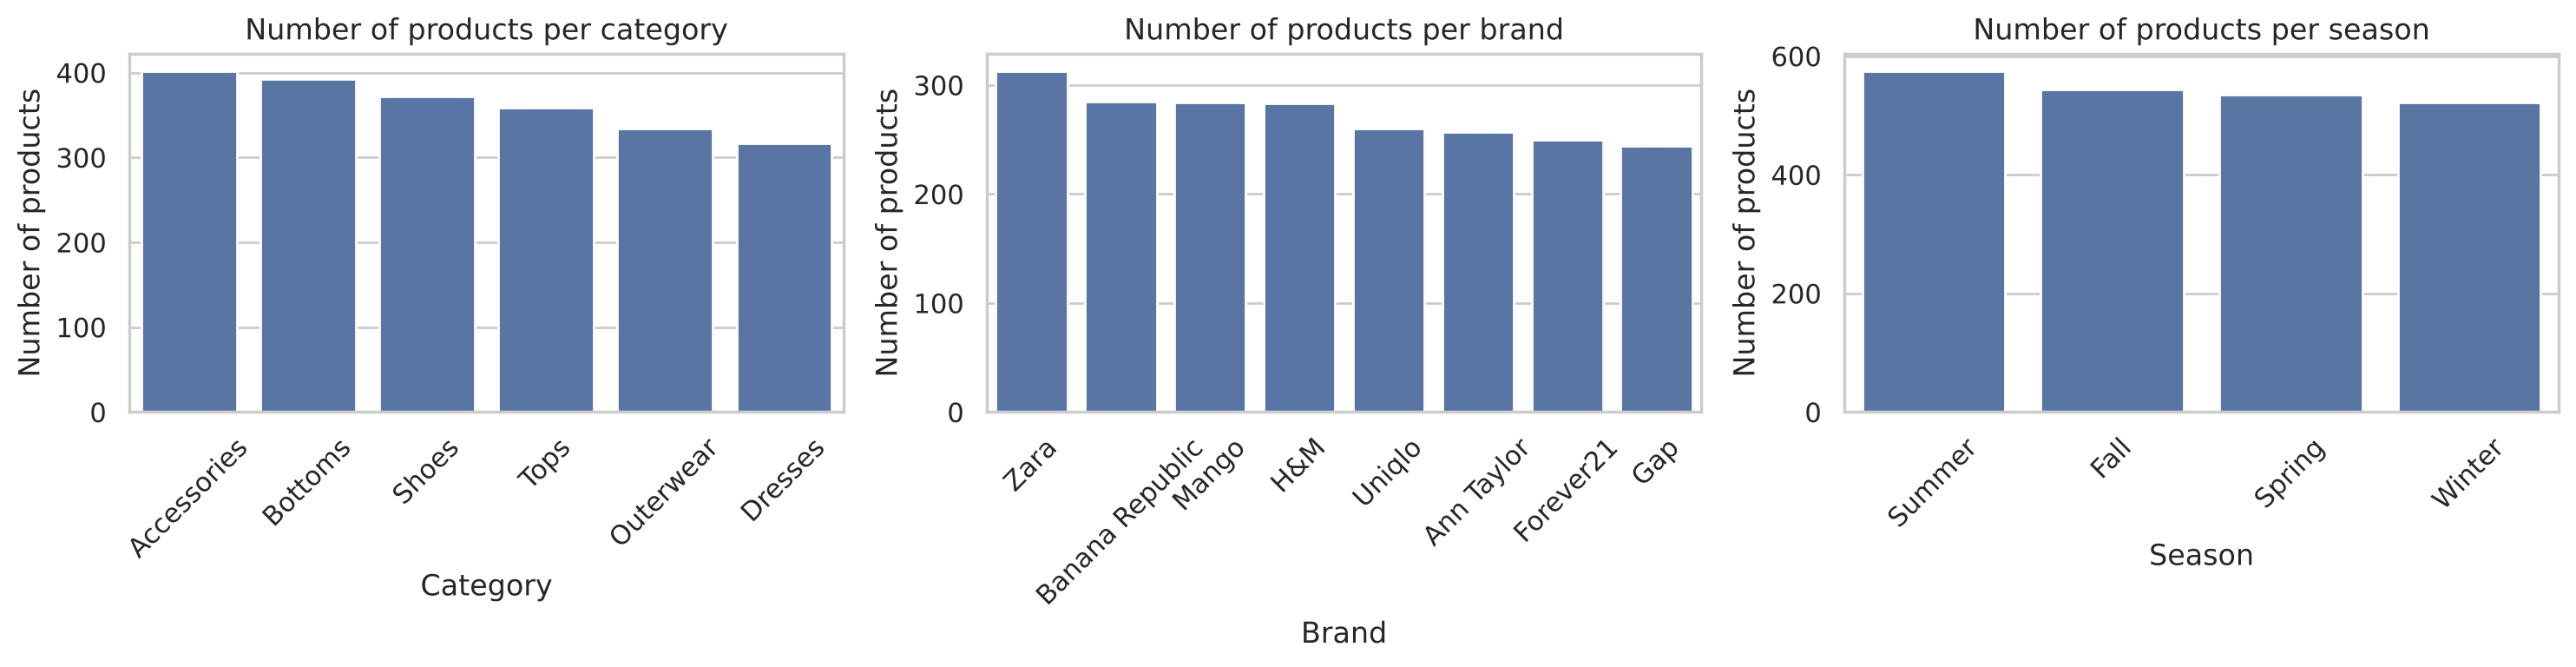

In [6]:
for col in ["category", "brand", "season", "size", "color"]:
    print(col)
    print(df[col].value_counts(dropna=False).to_string(), "\n")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["category", "brand", "season"]):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(f"Number of products per {col}")
    ax.set_xlabel(col.capitalize())
    ax.set_ylabel("Number of products")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

The groups are well balanced: no category, brand or season dominates.

### 2.5 Numeric distributions

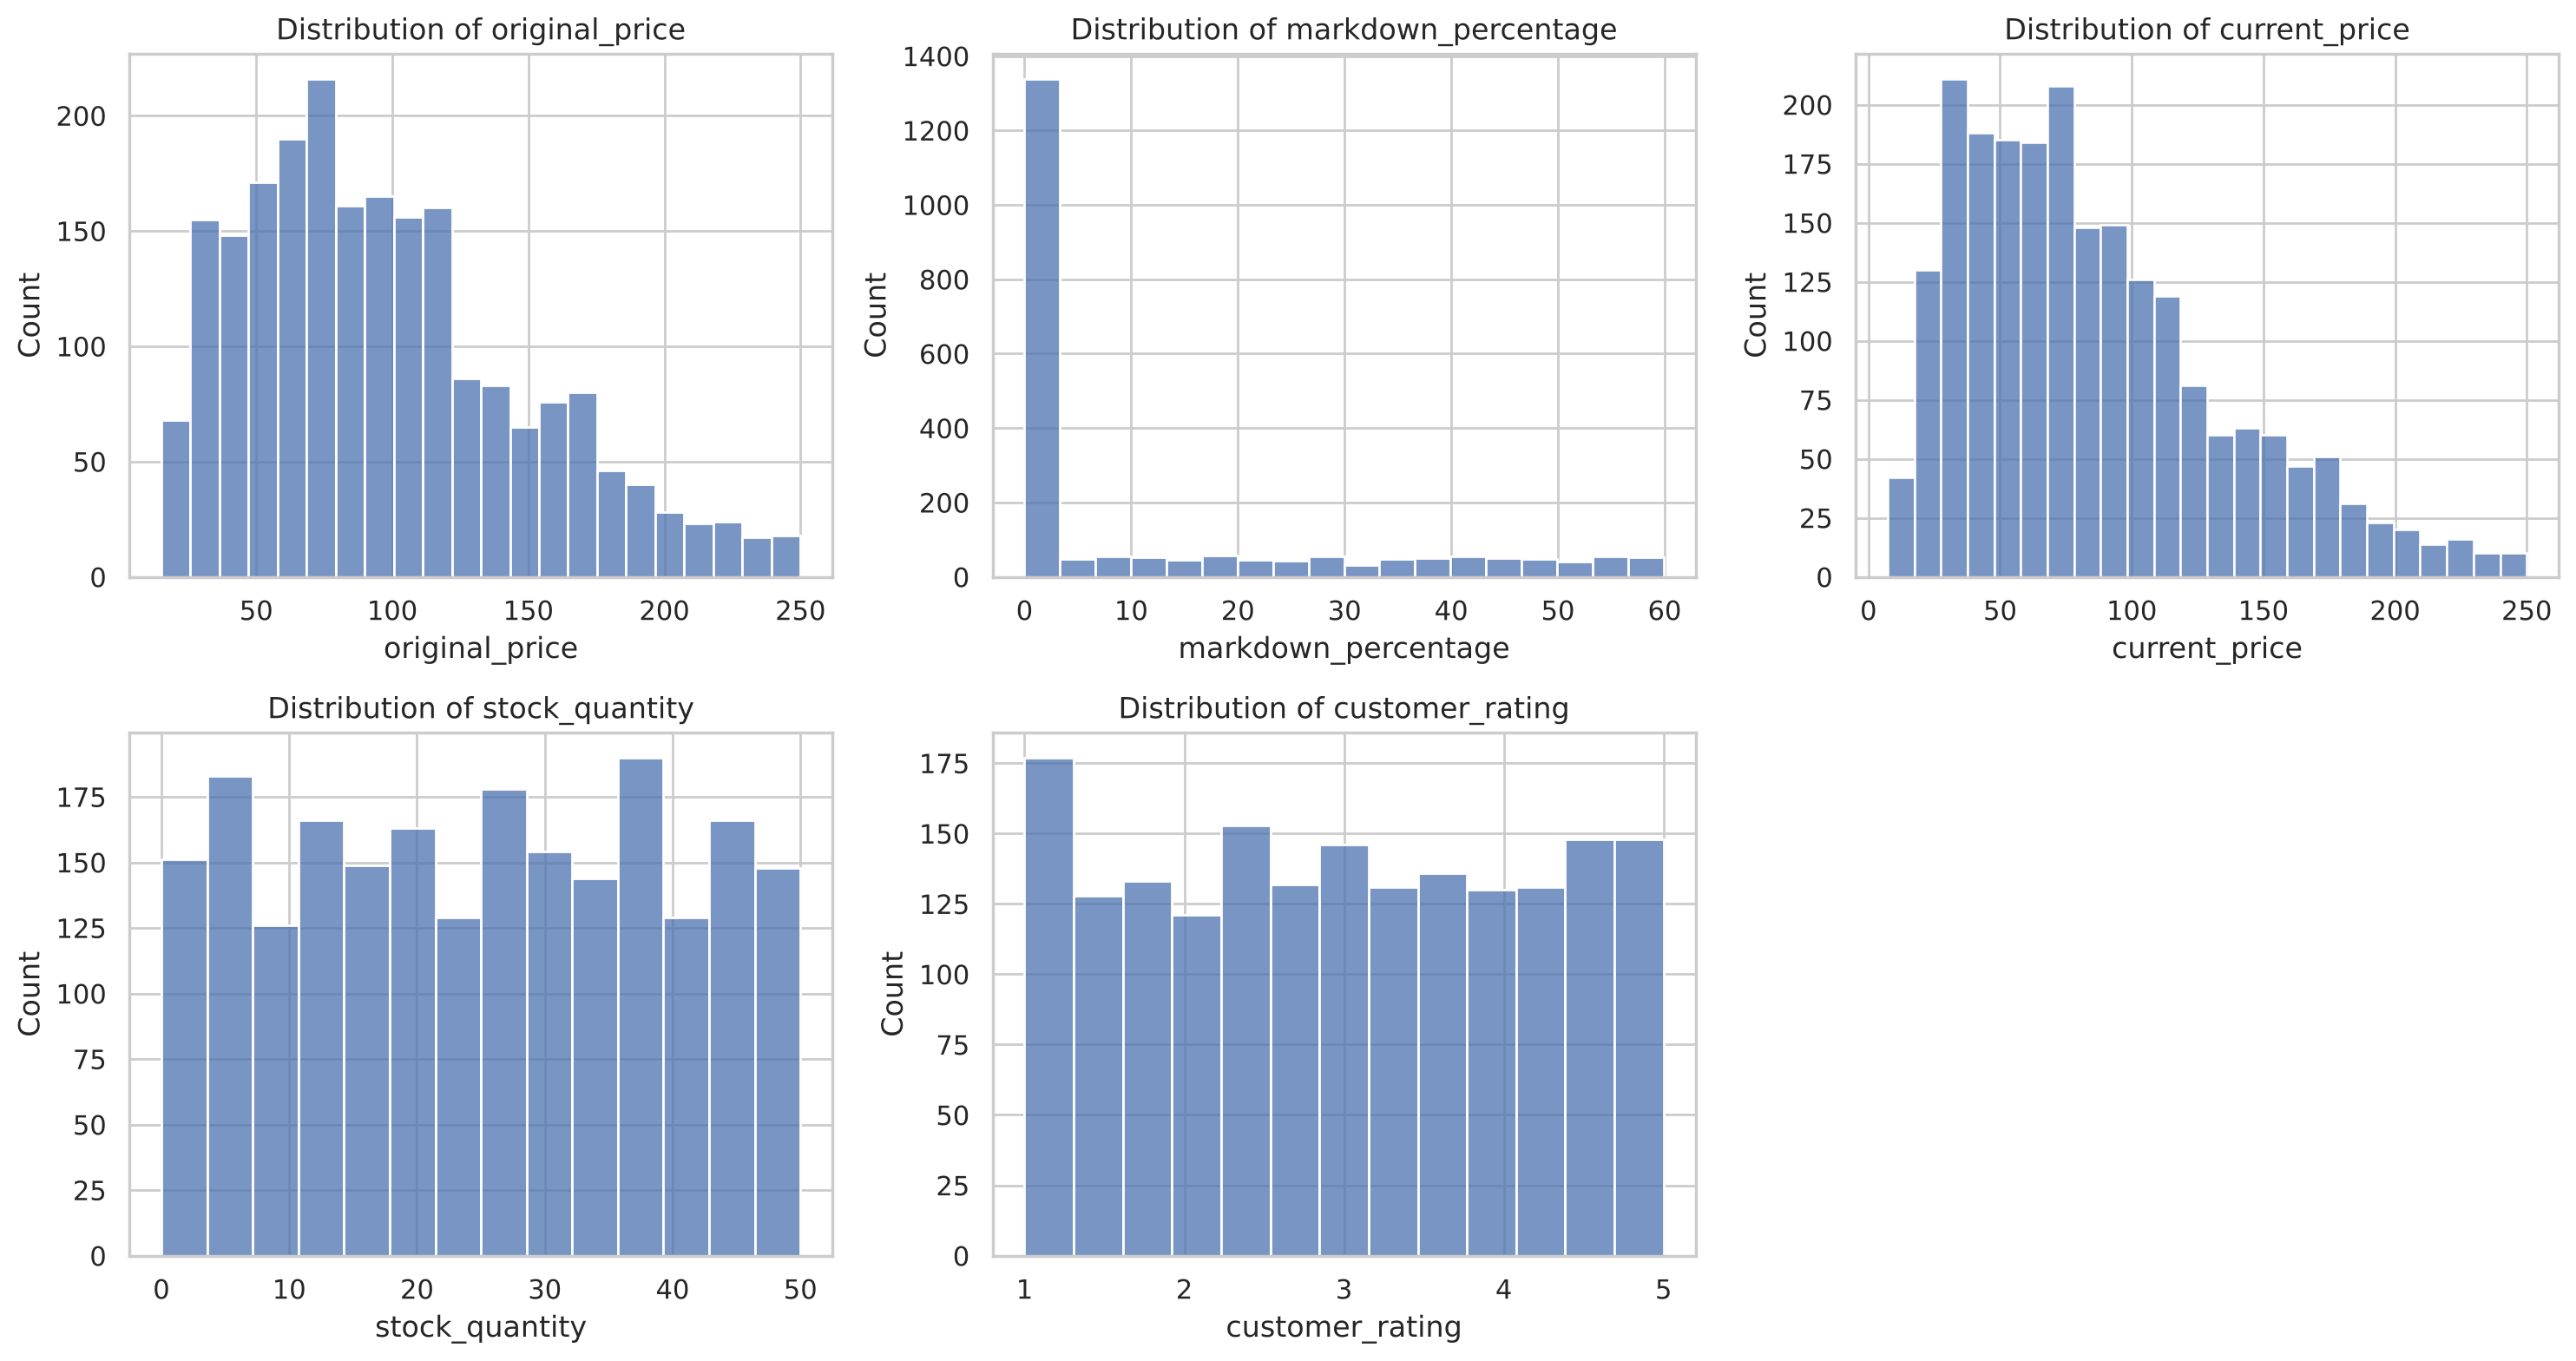

In [7]:
num_cols = ["original_price", "markdown_percentage", "current_price", "stock_quantity", "customer_rating"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=df, x=col, ax=ax)
    ax.set_title(f"Distribution of {col}")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

Markdown has one very tall bar at 0 (most items are not discounted) and an even spread of about 5% to 60% for the discounted items. Prices, stock and ratings are fairly evenly spread.

### 2.6 Key numbers and consistency checks

In [8]:
print("Returned items:", df["is_returned"].sum(), f"({df['is_returned'].mean():.1%})")
print("Marked-down items:", (df["markdown_percentage"] > 0).sum(), f"({(df['markdown_percentage'] > 0).mean():.1%})")

expected_price = df["original_price"] * (1 - df["markdown_percentage"] / 100)
print("Rows where current_price does not match the markdown:", (~np.isclose(expected_price, df["current_price"], atol=0.02)).sum())

print()
print("Most common purchase dates:")
print(df["purchase_date"].value_counts().head().to_string())

Returned items: 320 (14.7%)
Marked-down items: 878 (40.3%)
Rows where current_price does not match the markdown: 0

Most common purchase dates:
purchase_date
2025-08-06    1641
2025-04-25       6
2025-04-16       5
2024-09-13       5
2024-09-09       5


320 items were returned (14.7%) and 878 are marked down (40.3%). The price columns are consistent in every row.

### 2.7 First look at each question

These are only first impressions. The tests come later in the Modeling step.

category
Accessories    0.137
Bottoms        0.158
Dresses        0.148
Outerwear      0.162
Shoes          0.151
Tops           0.128 

brand
Ann Taylor         0.198
Banana Republic    0.165
Forever21          0.136
Gap                0.148
H&M                0.138
Mango              0.113
Uniqlo             0.127
Zara               0.153 

season
Fall      0.119
Spring    0.135
Summer    0.174
Winter    0.159 

size
L      0.176
M      0.133
S      0.136
XL     0.155
XS     0.159
XXL    0.133
NaN    0.141 



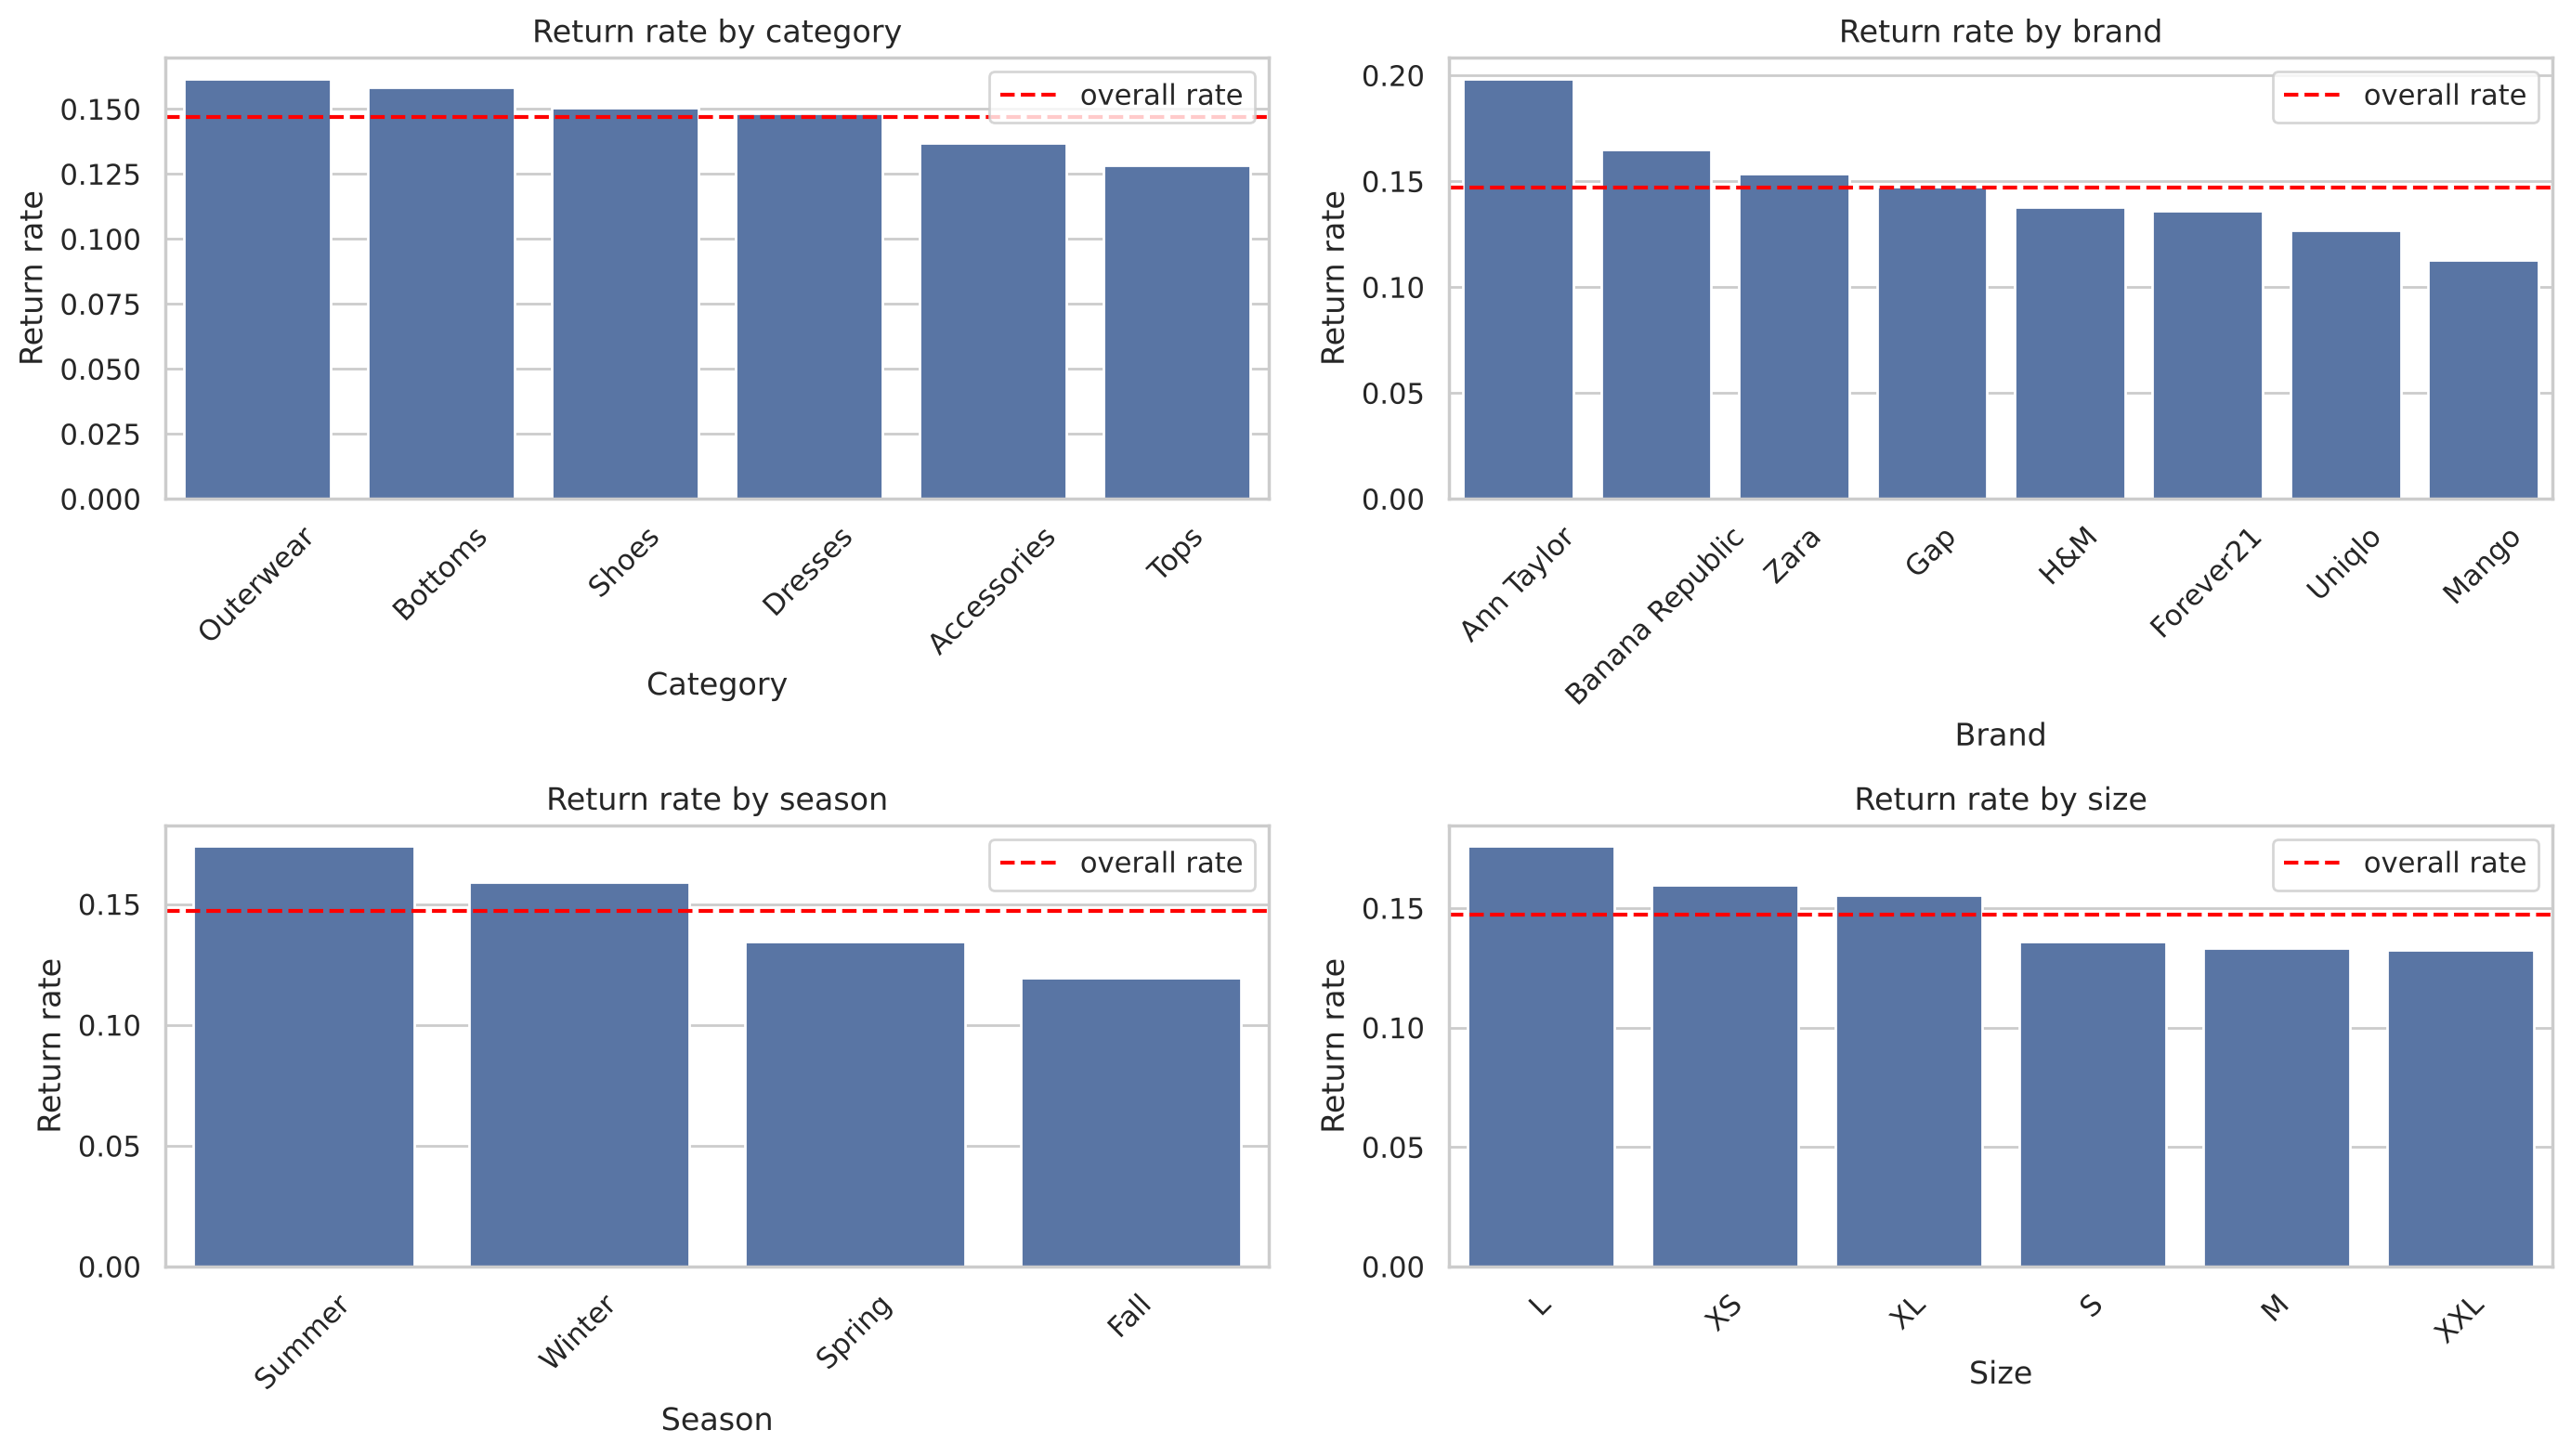

In [9]:
# Q1: return rate by product characteristics
for col in ["category", "brand", "season", "size"]:
    print(df.groupby(col, dropna=False)["is_returned"].mean().round(3).to_string(), "\n")

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.flat, ["category", "brand", "season", "size"]):
    rate = df.groupby(col)["is_returned"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.axhline(df["is_returned"].mean(), color="red", linestyle="--", label="overall rate")
    ax.set_title(f"Return rate by {col}")
    ax.set_xlabel(col.capitalize())
    ax.set_ylabel("Return rate")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
plt.tight_layout()
plt.show()

                     count  sum   mean
markdown_percentage                   
0%                    1298  186  0.143
1-20%                  303   36  0.119
21-40%                 278   55  0.198
40+%                   297   43  0.145


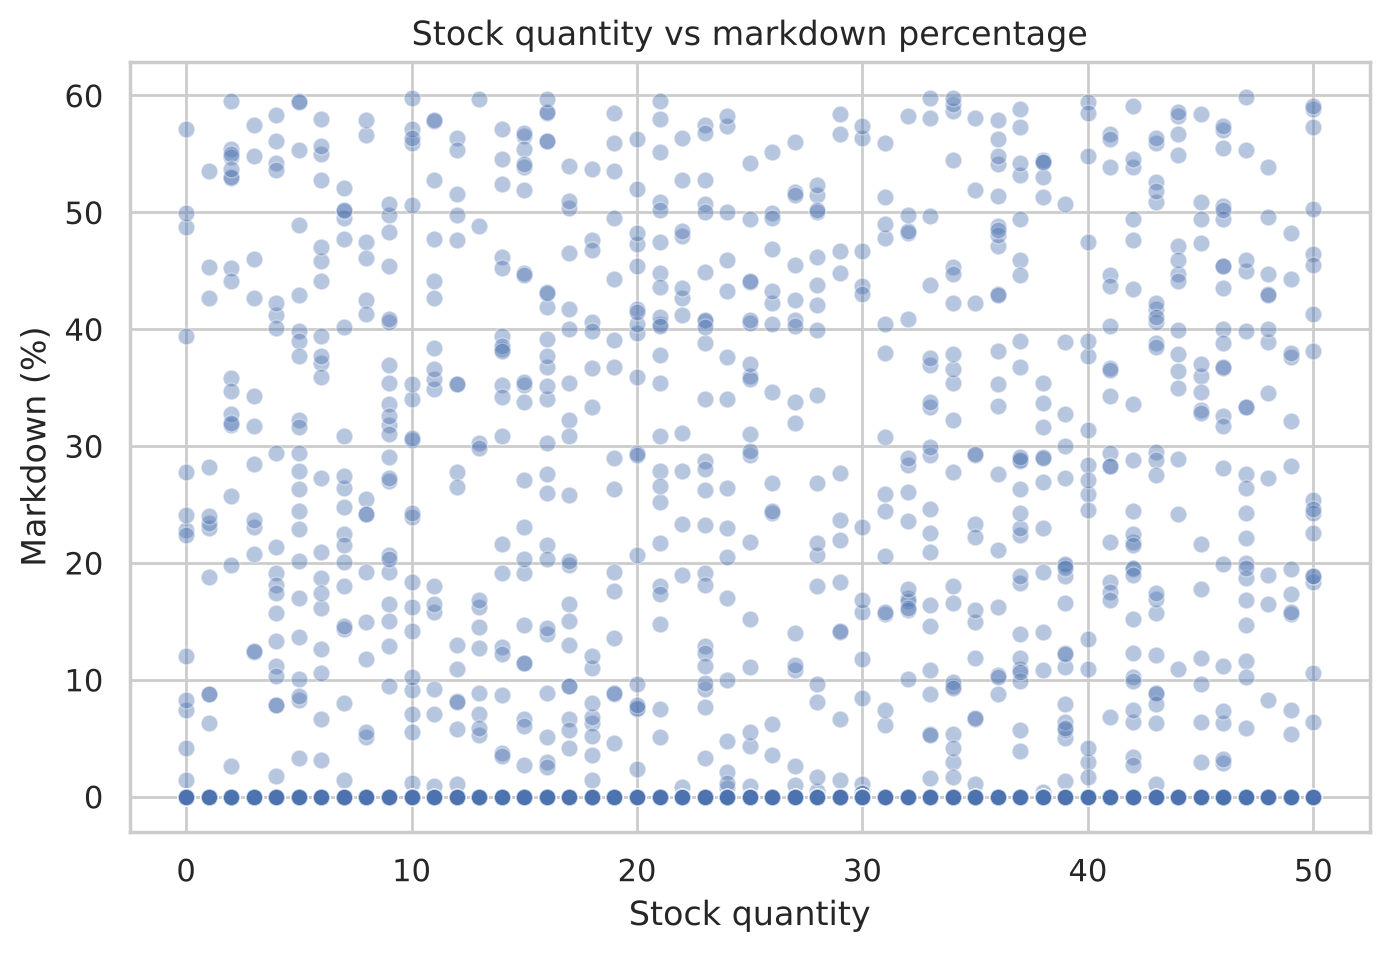

In [10]:
# Q2: return rate by markdown band (temporary bands, the final ones are made in Data Preparation)
temp_band = pd.cut(df["markdown_percentage"], bins=[-1, 0, 20, 40, 100], labels=["0%", "1-20%", "21-40%", "40+%"])
print(df.groupby(temp_band, observed=True)["is_returned"].agg(["count", "sum", "mean"]).round(3))

# Q3: stock vs markdown
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="stock_quantity", y="markdown_percentage", alpha=0.4)
plt.title("Stock quantity vs markdown percentage")
plt.xlabel("Stock quantity")
plt.ylabel("Markdown (%)")
plt.show()

### 2.8 Summary of Data Understanding

**Data quality**
- 2,176 products, 14 columns, no duplicates, and prices are consistent with the markdowns.
- Missing values in `size` (491), `customer_rating` (362) and `return_reason` (1,856, which are the items that were not returned).

**Unexpected findings**
- Markdown is mostly 0 and discounted items are evenly spread between about 5% and 60%.
- 75% of purchase dates are the same date, so the column is not used.
- Stock and ratings look evenly spread, which may mean the data is synthetic. This is a limitation.

**To fix in Data Preparation**
- Fill missing `size` values (Accessories as "N/A", the rest as "Unknown").
- Convert `is_returned` to 0/1 for the logistic regression.
- Create the markdown bands and a discounted flag.

**First impressions** (the differences are small and still need testing)
- **Q1:** return rates are close to the overall 14.7%. The biggest spread is between brands, from Mango (11.3%) to Ann Taylor (19.8%). Summer (17.4%) is the highest season and Fall (11.9%) the lowest.
- **Q2:** there is no steady increase with the discount. The 21-40% band has the highest return rate (19.8%), while the 40+% band (14.5%) is close to full-price items (14.3%).
- **Q3:** the scatter plot shows no visible pattern.

## 3. Data Preparation

I fill the missing sizes, convert the return flag to 0/1 and create the discount variables. `customer_rating`, `return_reason`, `color` and `purchase_date` are not used in the research questions, so they are left unchanged.

In [11]:
# Missing sizes: Accessories have no size (N/A), the other gaps are unknown
df["size"] = df["size"].fillna("Unknown")
df.loc[df["category"] == "Accessories", "size"] = "N/A"

# Return flag as 0/1 for the logistic regression
df["is_returned"] = df["is_returned"].astype(int)

# Discount variables
df["is_discounted"] = (df["markdown_percentage"] > 0).astype(int)
df["markdown_band"] = pd.cut(df["markdown_percentage"],
                             bins=[-1, 0, 20, 40, 100],
                             labels=["0%", "1-20%", "21-40%", "40+%"])

In [12]:
# Check the result
print(df[["category", "brand", "season", "size", "markdown_percentage", "stock_quantity", "is_returned"]].isna().sum())
print()
print(df["size"].value_counts().to_string())
print()
print(df["markdown_band"].value_counts().sort_index().to_string())

category               0
brand                  0
season                 0
size                   0
markdown_percentage    0
stock_quantity         0
is_returned            0
dtype: int64

size
N/A        402
XS         301
S          294
XL         283
XXL        279
L          273
M          255
Unknown     89

markdown_band
0%        1298
1-20%      303
21-40%     278
40+%       297


Sizes now show "N/A" for the 402 Accessories and "Unknown" for the 89 other gaps. The variables used in the analysis have no missing values.

**Outliers:** I checked the numeric variables with `describe()` and the histograms and removed no outliers.
- Prices (15.14 to 249.98 original, 7.29 to 249.98 current) are realistic, with no negative values.
- Markdown (0% to 59.9%) is a valid range. The many zeros are not outliers, since most items are simply not discounted.
- Stock (0 to 50) is plausible, and a stock of 0 is possible for sold-out items.

Unlike in project 1, no z-score removal or log transformation was needed, because the variables are bounded and the analysis uses a binary outcome and mostly categorical predictors.

## 4. Modeling

### 4.1 Q1: Which product characteristics are associated with higher return rates?

**Chi-square tests (one factor at a time).** For size, only rows with a real size are used.

In [13]:
results = []
for col in ["category", "brand", "season"]:
    table = pd.crosstab(df[col], df["is_returned"])
    chi2, p, dof, expected = chi2_contingency(table)
    results.append([col, round(chi2, 2), dof, round(p, 3)])

real_sizes = df[~df["size"].isin(["N/A", "Unknown"])]
table = pd.crosstab(real_sizes["size"], real_sizes["is_returned"])
chi2, p, dof, expected = chi2_contingency(table)
results.append(["size (real sizes only)", round(chi2, 2), dof, round(p, 3)])

pd.DataFrame(results, columns=["variable", "chi2", "degrees of freedom", "p-value"])

,variable,chi2,degrees of freedom,p-value
0,category,2.36,5,0.798
1,brand,10.19,7,0.178
2,season,7.86,3,0.049
3,size (real sizes only),3.38,5,0.642


Only season is below 0.05, and only barely (p = 0.049). With four tests, one result under 0.05 can easily be chance.

**Logistic regression (category, brand and season together).** The baseline groups are Accessories, Ann Taylor and Fall. Size is left out because "N/A" appears only for Accessories and would duplicate the category information.

In [14]:
model = smf.logit("is_returned ~ C(category) + C(brand) + C(season)", data=df).fit(disp=False)
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:            is_returned   No. Observations:                 2176
Model:                          Logit   Df Residuals:                     2160
Method:                           MLE   Df Model:                           15
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                 0.01117
Time:                        21:24:00   Log-Likelihood:                -898.49
converged:                       True   LL-Null:                       -908.64
Covariance Type:            nonrobust   LLR p-value:                    0.1610
===============================================================================================
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -1.6908      0.238     -7.100      0.000      -2.157      -1.224
C(category)[T.Bottoms]          0.1842      0.202      0.911      0.362      -0.212       0.580
C(category)[T.Dresses]          0.0990      0.216      0.458      0.647      -0.325       0.523
C(category)[T.Outerwear]        0.1918      0.209      0.917      0.359      -0.218       0.602
C(category)[T.Shoes]            0.1157      0.207      0.559      0.576      -0.290       0.521
C(category)[T.Tops]            -0.0811      0.216     -0.376      0.707      -0.504       0.342
C(brand)[T.Banana Republic]    -0.2611      0.225     -1.162      0.245      -0.702       0.179
C(brand)[T.Forever21]          -0.4895      0.244     -2.008      0.045      -0.967      -0.012
C(brand)[T.Gap]                -0.3637      0.240     -1.516      0.130      -0.834       0.107
C(brand)[T.H&M]                -0.4608      0.234     -1.968      0.049      -0.920      -0.002
C(brand)[T.Mango]              -0.6811      0.246     -2.768      0.006      -1.163      -0.199
C(brand)[T.Uniqlo]             -0.5202      0.244     -2.128      0.033      -0.999      -0.041
C(brand)[T.Zara]               -0.3210      0.223     -1.442      0.149      -0.758       0.115
C(season)[T.Spring]             0.0961      0.184      0.522      0.602      -0.265       0.457
C(season)[T.Summer]             0.4309      0.173      2.494      0.013       0.092       0.769
C(season)[T.Winter]             0.3090      0.180      1.721      0.085      -0.043       0.661
===============================================================================================
"""

In [15]:
conf = model.conf_int()
odds = pd.DataFrame({
    "odds_ratio": np.exp(model.params),
    "ci_low": np.exp(conf[0]),
    "ci_high": np.exp(conf[1]),
    "p_value": model.pvalues
}).round(3)
display(odds)

print("AUC:", round(roc_auc_score(df["is_returned"], model.predict(df)), 3))

,odds_ratio,ci_low,ci_high,p_value
Intercept,0.184,0.116,0.294,0.000
C(category)[T.Bottoms],1.202,0.809,1.787,0.362
C(category)[T.Dresses],1.104,0.723,1.686,0.647
C(category)[T.Outerwear],1.211,0.804,1.826,0.359
C(category)[T.Shoes],1.123,0.749,1.684,0.576
C(category)[T.Tops],0.922,0.604,1.407,0.707
C(brand)[T.Banana Republic],0.770,0.496,1.196,0.245
C(brand)[T.Forever21],0.613,0.380,0.988,0.045
C(brand)[T.Gap],0.695,0.434,1.113,0.130
C(brand)[T.H&M],0.631,0.399,0.998,0.049


AUC: 0.574


**Results**
- Pseudo R² = 0.011 and the overall model p-value = 0.161, so the model explains very little and is not significant overall.
- Category has no significant effect.
- Mango (odds ratio 0.51), Uniqlo (0.59), Forever21 (0.61) and H&M (0.63) have significantly lower odds of return than Ann Taylor.
- Summer items have about 54% higher odds of return than Fall (odds ratio 1.54, p = 0.013).
- **AUC = 0.574.** An AUC of 0.5 means no better than chance, so the model barely predicts returns, which agrees with the low pseudo R².

**Conclusion:** returns are only weakly related to product characteristics. Summer items and Ann Taylor products have somewhat higher return rates, but the differences are small.

**Caution:** Ann Taylor has the highest return rate and is the baseline, which makes the other brands look lower. Many coefficients were tested at once, so p-values just under 0.05 may be chance.

### 4.2 Q2: Do heavily discounted items get returned more often?

The baseline is the 0% band (full price).

In [16]:
table = pd.crosstab(df["markdown_band"], df["is_returned"])
chi2, p, dof, expected = chi2_contingency(table)
print("Chi-square p-value:", round(p, 3))

print(df.groupby("markdown_band", observed=True)["is_returned"].agg(["count", "sum", "mean"]).round(3))

Chi-square p-value: 0.05


               count  sum   mean
markdown_band                   
0%              1298  186  0.143
1-20%            303   36  0.119
21-40%           278   55  0.198
40+%             297   43  0.145


In [17]:
model2 = smf.logit("is_returned ~ C(markdown_band)", data=df).fit(disp=False)
model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:            is_returned   No. Observations:                 2176
Model:                          Logit   Df Residuals:                     2172
Method:                           MLE   Df Model:                            3
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                0.004101
Time:                        21:24:00   Log-Likelihood:                -904.91
converged:                       True   LL-Null:                       -908.64
Covariance Type:            nonrobust   LLR p-value:                   0.05878
==============================================================================================
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept                     -1.7882      0.079    -22.573      0.000      -1.943      -1.633
C(markdown_band)[T.1-20%]     -0.2156      0.194     -1.109      0.268      -0.597       0.165
C(markdown_band)[T.21-40%]     0.3883      0.170      2.283      0.022       0.055       0.722
C(markdown_band)[T.40+%]       0.0120      0.183      0.066      0.948      -0.347       0.371
==============================================================================================
"""

In [18]:
model3 = smf.logit("is_returned ~ C(markdown_band) + C(category) + C(brand) + C(season)", data=df).fit(disp=False)

def odds_table(m):
    conf = m.conf_int()
    return pd.DataFrame({
        "odds_ratio": np.exp(m.params),
        "ci_low": np.exp(conf[0]),
        "ci_high": np.exp(conf[1]),
        "p_value": m.pvalues
    }).round(3)

print("Markdown band only: pseudo R2 =", round(model2.prsquared, 3), ", overall p =", round(model2.llr_pvalue, 3))
display(odds_table(model2))

print("Markdown band + category, brand, season: pseudo R2 =", round(model3.prsquared, 3), ", overall p =", round(model3.llr_pvalue, 3))
display(odds_table(model3).loc[lambda t: t.index.str.contains("markdown_band")])

Markdown band only: pseudo R2 = 0.004 , overall p = 0.059


,odds_ratio,ci_low,ci_high,p_value
Intercept,0.167,0.143,0.195,0.000
C(markdown_band)[T.1-20%],0.806,0.551,1.180,0.268
C(markdown_band)[T.21-40%],1.475,1.056,2.058,0.022
C(markdown_band)[T.40+%],1.012,0.707,1.449,0.948


Markdown band + category, brand, season: pseudo R2 = 0.016 , overall p = 0.053


,odds_ratio,ci_low,ci_high,p_value
C(markdown_band)[T.1-20%],0.816,0.556,1.198,0.299
C(markdown_band)[T.21-40%],1.536,1.096,2.154,0.013
C(markdown_band)[T.40+%],0.997,0.694,1.430,0.985


**Results**
- Return rate by band: 0%: 14.3%, 1-20%: 11.9%, 21-40%: 19.8%, 40+%: 14.5%.
- Chi-square p = 0.050, just above the 0.05 threshold, so the differences between bands are borderline.
- Markdown band only: pseudo R² = 0.004, overall p = 0.059. Only the 21-40% band is significant (odds ratio 1.47, p = 0.022).
- With category, brand and season added: pseudo R² = 0.016, overall p = 0.053. The 21-40% band stays significant (odds ratio about 1.54, p = 0.013).
- The 1-20% and 40+% bands are not significantly different from full-price items.

**Conclusion:** heavily discounted items (40+%) are not returned more often than full-price items. Only moderately discounted items (21-40%) have higher odds of return. The effect is weak and the overall models are borderline significant, so it should be treated with caution.

### 4.3 Q3: Does high stock go with deeper markdowns?

In [19]:
rho, p = spearmanr(df["stock_quantity"], df["markdown_percentage"])
print(f"Spearman rho = {rho:.3f}, p = {p:.3f}")
print()
print(df.groupby("markdown_band", observed=True)["stock_quantity"].mean().round(1))

Spearman rho = 0.013, p = 0.540

markdown_band
0%        24.8
1-20%     25.5
21-40%    24.9
40+%      25.1
Name: stock_quantity, dtype: float64


**Result:** rho = 0.013 (p = 0.540), so there is no relationship between stock and markdown. The average stock is about 25 in every markdown band, which agrees with the shapeless scatter plot.

**Conclusion:** there is no evidence that overstock leads to deeper discounts.

**Caution:** stock quantity is probably a snapshot and not the stock level when the markdown was set. A correlation also cannot show that stock caused the markdown, and the data may be synthetic.

## 5. Evaluation

### Answers to the research questions

| **Question** | **Result** | **Evidence** |
|---|---|---|
| Q1: Which categories, brands, sizes or seasons have the highest return rate? | Weak effects only. Summer items and Ann Taylor products have somewhat higher return rates. Category and size have no effect. | Chi-square: category p = 0.798, brand p = 0.178, season p = 0.049, size p = 0.642. Logistic regression: pseudo R² = 0.011, overall p = 0.161, AUC = 0.574. Summer odds ratio 1.54 (p = 0.013) vs Fall. Mango, Uniqlo, H&M and Forever21 have lower odds than Ann Taylor (odds ratios 0.51 to 0.63). |
| Q2: Do heavily discounted items get returned more often? | No. Only moderately discounted items (21-40%) have higher odds of return. | Chi-square p = 0.050 (borderline). 21-40% band odds ratio 1.47 (p = 0.022), and about 1.54 (p = 0.013) after adjusting for category, brand and season. 1-20% and 40+% bands not significant. Overall model p = 0.059 and 0.053. |
| Q3: Does high stock go with deeper markdowns? | No relationship. | Spearman rho = 0.013, p = 0.540. Average stock is about 25 in every markdown band. |

### Business goal

The goal was to find ways to reduce returns and improve markdown decisions. The analysis shows that returns are hard to predict from the available product information: the models explain only 1-2% of the variation (pseudo R² between 0.004 and 0.016). The Q1 model's AUC of 0.574 is only slightly better than chance (0.5), which confirms that returns are hard to predict from these variables. The clearest findings are that returns are higher in Summer and for Ann Taylor, and that items marked down by 21-40% are returned more often than full-price items. Heavy discounts (40+%) do not raise returns, and stock level does not drive markdowns.

### Limitations

- **Associations, not causal effects.** The analysis cannot show that a season, brand or discount causes returns.
- **Weak models.** Pseudo R² is at most 0.016, and the overall significance of the models is borderline (p between 0.05 and 0.16). The data lacks important factors such as customer information, product quality and sales volume.
- **Multiple testing.** Many tests and coefficients were examined, so some p-values just below 0.05 (for example season in the chi-square test, p = 0.049) may be due to chance.
- **Baseline choice.** Ann Taylor, the baseline brand, has the highest return rate, which makes the other brands look significantly lower.
- **Size.** Size was not included in the regression because "N/A" appears only for Accessories and would duplicate the category information. About 4% of the sizes of non-accessory items were missing and labelled "Unknown".
- **Data quality.** 75% of purchase dates are the same date, so time effects could not be studied. Stock is probably a snapshot and not the stock level when the markdown was set. The even spread of stock and ratings suggests the data may be synthetic.
- **Missing ratings.** 17% of customer ratings are missing, and the variable was not used.

## 6. Deployment

### Recommendations for the boutique

1. **Review the Ann Taylor range and Summer items first.** Ann Taylor products (19.8% return rate) and Summer items (17.4%) are returned most often, and Summer items had about 54% higher odds of return than Fall items. The boutique could check these products for quality, sizing or description problems. The effect is small and should be confirmed with more data before making big changes.
2. **Do not assume that heavy discounts increase returns.** Items marked down by 40% or more are returned at the same rate as full-price items (about 14.5% vs 14.3%), so deep clearance discounts do not seem to create extra return costs.
3. **Look at moderate discounts (21-40%) more closely.** This band had the highest return rate (19.8%) and about 47-54% higher odds of return than full-price items. The boutique could check whether these items differ in some way, such as the product mix or promotion style, and track whether the pattern repeats.
4. **Review how markdown decisions are made.** Stock quantity was unrelated to markdown percentage (rho = 0.013), so markdowns do not seem to follow stock levels. The boutique could check whether its markdown rules should take stock into account.
5. **Collect richer data.** The available variables explain very little of the returns (pseudo R² of at most 0.016, AUC = 0.574). Adding customer information, product quality scores, sales volume and the date of the markdown would allow a much more useful analysis.

### Limits of these recommendations

All findings are associations and not proof of cause and effect. The effects are small and the models are only borderline significant, so the recommendations are suggestions to investigate and not firm rules.

### Next steps

- Repeat the analysis when more data is available, especially with customer and sales information.
- Test changes on a small scale, for example a different markdown level or a revised product description for Summer items, and compare return rates before and after.